DATASET LOADED
   Unnamed: 0                              College_Name       State    UG_fee  \
0           0    Indian Institute of Technology Madras   Tamil nadu     75116   
1           1  College of Engineering, Anna University   Tamil nadu     50000   
2           2              NIT Trichy, Tiruchirappalli   Tamil nadu  1,49,250   
3           3          Vellore Institute of Technology   Tamil nadu  1,98,000   
4           4     SRM Engineering College, Kanchipuram   Tamil nadu  2,60,000   

     PG_fee Rating Academic Accommodation Faculty Infrastructure Placement  \
0     23070    8.7        9           7.9     8.7            8.8       8.8   
1     50000    8.4      8.7           7.7     8.1            8.7       8.3   
2     99250    8.5      8.6           7.8     8.2            8.7       8.8   
3  1,83,000    8.3      8.3             8     7.8            8.9       8.5   
4  1,70,000    7.2      6.5           6.6     6.9            7.6       7.1   

  Social_Life  
0           9

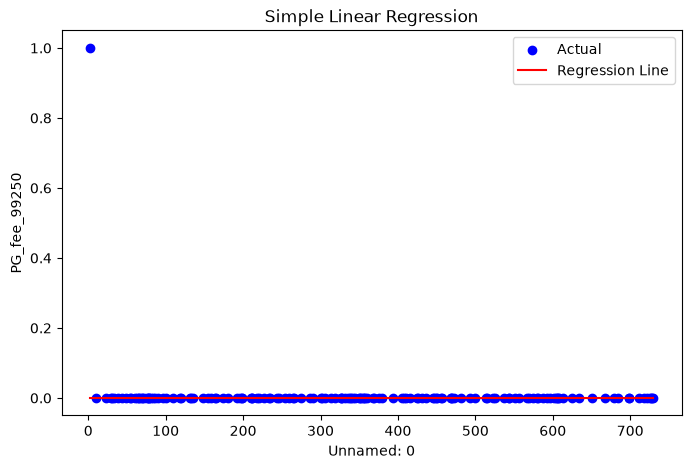


========== MULTIPLE LINEAR REGRESSION ==========
Intercept: 0.0
MAE: 0.006802721088435374
MSE: 0.006802721088435374
R2 Score: -0.0068493150684934


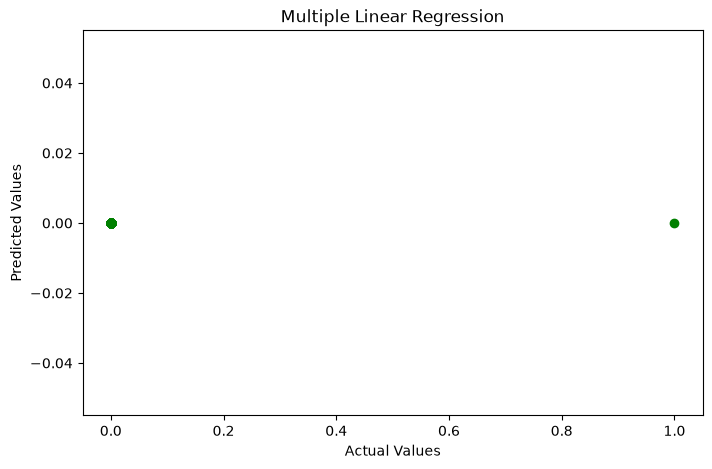


========== PCA RESULTS ==========
        PC1       PC2
0  5.067272 -0.980953
1  3.454645 -1.749532
2  3.292156 -1.311613
3  3.127651 -1.683929
4 -1.321227 -2.662741

Original Features: 1504
Reduced Features: 2

Explained Variance:
[0.00508322 0.00270342]

Total Explained Variance: 0.00778664033010831


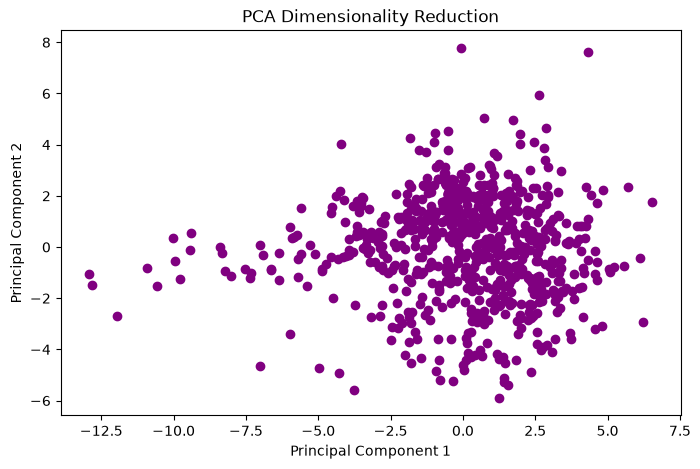

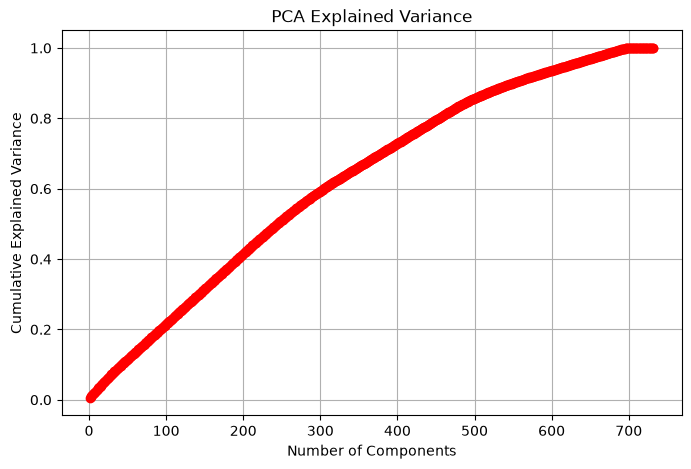


========== FINAL COMPARISON ==========
Simple Linear Regression R2: -0.0068493150684934
Multiple Linear Regression R2: -0.0068493150684934

ALL THREE METHODS COMPLETED!


In [9]:
# ============================================================
# SIMPLE LINEAR REGRESSION
# MULTIPLE LINEAR REGRESSION
# PCA - DIMENSIONALITY REDUCTION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


# 1. LOAD DATASET

file_path = "Colleges_Dataset.csv"

df = pd.read_csv(file_path)

print("DATASET LOADED")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())
print("\nData Types:\n", df.dtypes)


# 2. DATA PREPROCESSING

# Remove duplicate rows
df = df.drop_duplicates()

# Remove columns containing only missing values
df = df.dropna(axis=1, how='all')

# Convert numerical-looking text columns into numbers (pandas 2.x & 3.x compatible)
for col in df.columns:
    if pd.api.types.is_string_dtype(df[col]):
        converted = pd.to_numeric(df[col], errors='coerce')

        if converted.notna().sum() > 0:
            if converted.notna().mean() >= 0.8:
                df[col] = converted

# Separate numerical and categorical columns
numeric_df = df.select_dtypes(include=np.number).copy()

# Include 'string' alongside 'object' to avoid Pandas4Warning
categorical_df = df.select_dtypes(
    include=['object', 'string', 'category', 'bool']
).copy()

# Fill missing numerical values
if numeric_df.shape[1] > 0:
    numeric_df = numeric_df.fillna(numeric_df.mean())

# Encode categorical columns
if categorical_df.shape[1] > 0:
    categorical_df = categorical_df.fillna('Unknown')
    categorical_df = pd.get_dummies(
        categorical_df,
        drop_first=True,
        dtype=int
    )

# Combine numerical and encoded categorical columns
data = pd.concat([numeric_df, categorical_df], axis=1)

# Remove constant columns
data = data.loc[:, data.nunique() > 1]

print("\nProcessed Dataset:")
print(data.head())


if data.shape[1] < 2:
    raise ValueError(
        "Your dataset needs at least two useful features. "
        "Check the printed columns and dataset contents."
    )


# 3. SELECT TARGET COLUMN

# Select the last available column as target
target_column = data.columns[-1]

print("\nTarget Column:", target_column)

X = data.drop(columns=[target_column])
y = data[target_column]


# 4. TRAIN TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# ============================================================
# 5. SIMPLE LINEAR REGRESSION
# ============================================================

X_simple = X.iloc[:, [0]]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

simple_model = LinearRegression()

simple_model.fit(X_train_s, y_train_s)

simple_pred = simple_model.predict(X_test_s)

print("\n========== SIMPLE LINEAR REGRESSION ==========")

print("Feature:", X_simple.columns[0])
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_)

print("MAE:", mean_absolute_error(y_test_s, simple_pred))
print("MSE:", mean_squared_error(y_test_s, simple_pred))
print("R2 Score:", r2_score(y_test_s, simple_pred))

plt.figure(figsize=(8, 5))

plt.scatter(
    X_test_s.iloc[:, 0],
    y_test_s,
    color='blue',
    label='Actual'
)

sorted_index = np.argsort(X_test_s.iloc[:, 0].values)

plt.plot(
    X_test_s.iloc[:, 0].values[sorted_index],
    simple_pred[sorted_index],
    color='red',
    label='Regression Line'
)

plt.xlabel(X_simple.columns[0])
plt.ylabel(target_column)
plt.title('Simple Linear Regression')
plt.legend()
plt.show()


# ============================================================
# 6. MULTIPLE LINEAR REGRESSION
# ============================================================

multiple_model = LinearRegression()

multiple_model.fit(X_train, y_train)

multiple_pred = multiple_model.predict(X_test)

print("\n========== MULTIPLE LINEAR REGRESSION ==========")

print("Intercept:", multiple_model.intercept_)

print("MAE:", mean_absolute_error(y_test, multiple_pred))
print("MSE:", mean_squared_error(y_test, multiple_pred))
print("R2 Score:", r2_score(y_test, multiple_pred))

plt.figure(figsize=(8, 5))

plt.scatter(y_test, multiple_pred, color='green')

plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Multiple Linear Regression')

plt.show()


# ============================================================
# 7. PCA - DIMENSIONALITY REDUCTION
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Select maximum two components
n_components = min(2, X.shape[1], X.shape[0])

pca = PCA(n_components=n_components)

X_reduced = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_reduced,
    columns=[f'PC{i+1}' for i in range(n_components)]
)

print("\n========== PCA RESULTS ==========")

print(pca_df.head())

print("\nOriginal Features:", X.shape[1])
print("Reduced Features:", n_components)

print("\nExplained Variance:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:",
      sum(pca.explained_variance_ratio_))


# PCA Visualization

if n_components == 2:

    plt.figure(figsize=(8, 5))

    plt.scatter(
        pca_df['PC1'],
        pca_df['PC2'],
        color='purple'
    )

    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.title('PCA Dimensionality Reduction')

    plt.show()


# ============================================================
# 8. PCA EXPLAINED VARIANCE
# ============================================================

pca_full = PCA()

pca_full.fit(X_scaled)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o',
    color='red'
)

plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Explained Variance')

plt.grid()
plt.show()


# ============================================================
# 9. FINAL COMPARISON
# ============================================================

print("\n========== FINAL COMPARISON ==========")

print("Simple Linear Regression R2:",
      r2_score(y_test_s, simple_pred))

print("Multiple Linear Regression R2:",
      r2_score(y_test, multiple_pred))

print("\nALL THREE METHODS COMPLETED!")
